# RePaint v2: reaching the paper benchmark, plus adaptive resampling
*Lugmayr et al., "RePaint: Inpainting using Denoising Diffusion Probabilistic Models", CVPR 2022 · [arXiv:2201.09865](https://arxiv.org/abs/2201.09865)*

v1 implemented the algorithm correctly. Resampling beat r = 1 on every mask, and Super-Resolve 2× and Alternating Lines landed close to the paper. Wide, Narrow, Half and Expand stayed well behind (LPIPS 0.098 / 0.051 / 0.191 / 0.469 vs. 0.059 / 0.028 / 0.165 / 0.435). The remaining gap came from **what RePaint was conditioning**, not from the sampler. This notebook closes it with the strategies below. Section 14 explains each one in detail.

| # | Strategy | v1 | v2 |
|---|---|---|---|
| S1 | **The paper's diffusion prior** | `google/ddpm-celebahq-256`, raw (non-EMA) weights, 114 M params | The authors' own CelebA-HQ checkpoint `celeba256_250000.pt` (ADM / guided-diffusion, 553 M params, EMA). Falls back to `google/ddpm-ema-celebahq-256` |
| S2 | **Learned reverse variance** | Fixed posterior variance | The model's learned Σθ (interpolated log-variance), as in the paper's model |
| S3 | **The paper's test data** | CelebA 178×218 JPEGs, center-cropped and upscaled 1.4× | The official CelebA-HQ 256×256 test images *and* the exact LaMa masks used in Table 1 (from the authors' `data.zip`) |
| S4 | **CelebA-HQ alignment** (fallback only) | Plain center crop | Eye/mouth-anchored crop that reproduces CelebA-HQ's face scale and position |
| S5 | **Adaptive resampling** (extension, not in the paper) | Fixed r = 10 at every jump | Per-sample, harmony-driven: keep resampling while the model's x̂₀ still disagrees with the known pixels at the hole boundary (r between 5 and 15), keep the most harmonious state, and drop converged samples from the batch so compute is actually saved |
| S6 | Kaggle engineering | — | 12 h time budget with priority scheduling, resume from a previous run's output, OOM-safe batch sizing, two-GPU work queue |

**Kaggle settings:** *Accelerator → GPU T4 ×2*, *Internet → On*. The zip dataset from v1 is now **optional**: it is only used if the official test set cannot be downloaded.

## 0 · Configuration — **edit this cell**

In [1]:
# ============================== W&B =========================================
WANDB_API_KEY  = ""                               # <-- paste your W&B API key (or add a Kaggle Secret named WANDB_API_KEY)
WANDB_PROJECT  = "repaint-cvpr22-benchmark-Attemp2"       # <-- change project name
WANDB_ENTITY   = None                             # <-- your W&B username / team (None = default)
WANDB_RUN_NAME = "v2-paper-ckpt-celebahq5-adaptive-resample"  # <-- change run name
WANDB_TAGS     = ["repaint", "v2", "adaptive-resampling", "celebahq"]

# ============================== What to run on ==============================
BACKEND  = "auto"    # "paper" = authors' celeba256_250000.pt | "hf" = google/ddpm-ema-celebahq-256 | "auto" = paper, else hf
DATASET  = "auto"    # "paper" = official CelebA-HQ test set + LaMa masks | "zip" = your CelebA zip | "auto" = paper, else zip
N_IMAGES = 5         # the paper averages over 100; 5 keeps the run inside one Kaggle session
IMAGE_SELECTION = "random"   # "random" (seeded) or a list of indices into the 100 test images, e.g. [0, 7, 21, 42, 63]
SEED = 2022

# ============================== RePaint (paper Table 1 settings) ============
T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE = 250, 10, 10
MASK_TYPES = ["wide", "narrow", "sr2x", "altlines", "half", "expand"]
N_DIVERSITY = 2                       # extra seeds of image #1 on Half / Expand

# ============================== Adaptive resampling (S5) ====================
RUN_ADAPTIVE = True
ADAPTIVE = dict(
    r_min=5,          # every jump point gets at least this many passes (paper: 10 for all)
    r_max=15,         # hard samples may get up to this many (paper Table 3: r = 15 helps)
    tol=0.02,         # keep resampling while boundary disharmony improves by > 2 % per round
    band_px=16,       # width of the known-pixel band around the hole used to measure harmony
    pool=4,           # compare at 1/4 resolution, so blur in x0_hat is not mistaken for disharmony
    keep_best=True,   # leave each jump point with the most harmonious state seen
)

# ============================== Other experiments ===========================
RUN_BASELINE_NO_RESAMPLING = True     # r = 1: shows what resampling buys (cheap: ~10 % of the main run)
RUN_ABLATION_JR       = False         # paper Table 3 (j x r grid). Expensive with the paper model; v1 already ran it
RUN_ABLATION_SLOWDOWN = False         # paper Table 2
ABLATION_J, ABLATION_R = [1, 5, 10], [5, 10, 15]
SLOWDOWN_T, RESAMPLE_R = [250, 500, 750, 1000], [1, 2, 3, 4]

# ============================== Compute =====================================
TIME_BUDGET_HOURS = 10     # Kaggle hard limit is 12 h; experiments that would not fit are skipped (and can be resumed)
MAX_BATCH_PER_GPU = None     # None = auto (largest batch that fits)
USE_FP16 = True
DRY_RUN  = False             # True = tiny step counts, smoke-test everything in minutes

# Official RePaint assets (from the authors' download.sh)
REPAINT_REPO = "https://github.com/andreas128/RePaint.git"
GDRIVE_CKPT_IDS = ["1norNWWGYP3EZ_o05DmoW1ryKuKMmhlCX", "1QEl-btGbzQz6IwkXiFGd49uQNTUtTHsk"]  # one of them is celeba256_250000.pt
GDRIVE_DATA_ID  = "1Q_dxuyI41AAmSv9ti3780BwaJQqwvwMv"   # data.zip: CelebA-HQ test images + LaMa test masks

## 1 · Setup: packages, hardware, official RePaint code
The authors' repository is cloned for its `guided_diffusion` network definition. That code is needed to load their checkpoint. The sampler itself is implemented in this notebook (section 5).

In [2]:
import subprocess, sys, importlib, os
def _pip(*pkgs): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
need = [p for p, m in [("lpips", "lpips"), ("wandb", "wandb"), ("diffusers", "diffusers"), ("gdown", "gdown"),
                       ("opencv-python-headless", "cv2"), ("scikit-image", "skimage"), ("pyyaml", "yaml")]
        if importlib.util.find_spec(m) is None]
if need: print("Installing", need); _pip(*need)

from pathlib import Path
import shutil, zipfile, glob
INPUT_ROOT   = Path(os.environ.get("REPAINT_INPUT_ROOT", "/kaggle/input"))
WORKING_ROOT = Path(os.environ.get("REPAINT_WORKING_ROOT", "/kaggle/working"))
WORKING_ROOT.mkdir(parents=True, exist_ok=True)
REPO_DIR = WORKING_ROOT / "RePaint"
if not (REPO_DIR / "guided_diffusion").exists():
    r = subprocess.run(["git", "clone", "-q", "--depth", "1", REPAINT_REPO, str(REPO_DIR)], capture_output=True, text=True)
    print("git clone:", "ok" if r.returncode == 0 else r.stderr[-500:])
if str(REPO_DIR) not in sys.path: sys.path.insert(0, str(REPO_DIR))
OUT_DIR = WORKING_ROOT / "repaint_outputs"
FIG_DIR, CACHE_DIR, ASSET_DIR = OUT_DIR / "figures", OUT_DIR / "cache", WORKING_ROOT / "repaint_assets"
for d in (OUT_DIR, FIG_DIR, CACHE_DIR, OUT_DIR / "samples", ASSET_DIR): d.mkdir(parents=True, exist_ok=True)
print("RePaint code:", REPO_DIR, "| outputs:", OUT_DIR)

Installing ['lpips']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.9 MB/s eta 0:00:00
git clone: ok
RePaint code: /kaggle/working/RePaint | outputs: /kaggle/working/repaint_outputs


In [3]:
import time, math, random, json, threading, queue, warnings, types
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", category=UserWarning)
START_TIME = time.time()
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICES = [torch.device(f"cuda:{i}") for i in range(torch.cuda.device_count())] or [torch.device("cpu")]
MAIN_DEVICE = DEVICES[0]; IS_CUDA = MAIN_DEVICE.type == "cuda"
if IS_CUDA: torch.backends.cudnn.benchmark = True
USE_FP16 = USE_FP16 and IS_CUDA
if DRY_RUN:
    T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE = 20, 5, 2
    ADAPTIVE.update(r_min=2, r_max=3)
    ABLATION_J, ABLATION_R, SLOWDOWN_T, RESAMPLE_R = [1, 5], [2, 3], [20, 40], [1, 2]
print(f"PyTorch {torch.__version__} | {len(DEVICES)} device(s):",
      ", ".join(torch.cuda.get_device_name(d) for d in DEVICES) if IS_CUDA else "cpu", f"| fp16={USE_FP16}")

def hours_left(): return TIME_BUDGET_HOURS - (time.time() - START_TIME) / 3600

C_OURS, C_BASE, C_ADA, C_PAPER, C_V1, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e87ba4", "#a9a8a2"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "savefig.bbox": "tight", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
MASK_LABEL = {"wide": "Wide", "narrow": "Narrow", "sr2x": "Super-Resolve 2×", "altlines": "Altern. Lines",
              "half": "Half", "expand": "Expand"}

PyTorch 2.11.0+cu128 | 2 device(s): Tesla T4, Tesla T4 | fp16=True


## 2 · Official assets: the paper's checkpoint and test set (S1, S3)
Lookup order for each asset:
1. Any Kaggle input you attached. For example, if `gdown` hits Google Drive's download quota, download `celeba256_250000.pt` and `data.zip` yourself from the [RePaint repo](https://github.com/andreas128/RePaint) and add them as a Kaggle dataset.
2. Download from the authors' Google Drive links (`download.sh`).
3. Fallback: the public EMA DDPM, and your CelebA zip with CelebA-HQ alignment.

In [4]:
import gdown

def find_in_inputs(pattern):
    hits = sorted(INPUT_ROOT.rglob(pattern)) if INPUT_ROOT.exists() else []
    return hits[0] if hits else None

def gdrive(file_id, out_dir):
    try:
        out = gdown.download(f"https://drive.google.com/uc?id={file_id}", output=str(out_dir) + "/", quiet=False)
        return Path(out) if out else None
    except Exception as e:
        print(f"  gdown {file_id} failed: {type(e).__name__}: {str(e)[:200]}")
        return None

# ---------- checkpoint ----------
PAPER_CKPT = None
if BACKEND in ("auto", "paper"):
    PAPER_CKPT = find_in_inputs("celeba256_250000.pt") or next(iter(ASSET_DIR.glob("celeba256_250000.pt")), None)
    if PAPER_CKPT is None:
        for fid in GDRIVE_CKPT_IDS:
            print(f"Downloading paper checkpoint candidate {fid} (~2.1 GB)...")
            p = gdrive(fid, ASSET_DIR)
            if p is not None and "celeba" in p.name.lower():
                PAPER_CKPT = p; break
            elif p is not None:
                print(f"  got {p.name} (not the CelebA-HQ model), removing"); p.unlink(missing_ok=True)
    if PAPER_CKPT is None and BACKEND == "paper":
        raise RuntimeError("Could not obtain celeba256_250000.pt — attach it as a Kaggle dataset.")
BACKEND_USED = "paper" if PAPER_CKPT is not None else "hf"
print("Backend:", BACKEND_USED, "|", PAPER_CKPT or "google/ddpm-ema-celebahq-256")

# ---------- official test set ----------
def find_official_data(root):
    if root is None or not root.exists(): return None
    for g in sorted(root.rglob("c256")):
        if g.is_dir() and g.parent.name == "gts":
            masks = g.parent.parent / "gt_keep_masks"
            if masks.exists(): return g, masks
    return None

OFFICIAL = None
if DATASET in ("auto", "paper"):
    OFFICIAL = find_official_data(INPUT_ROOT) or find_official_data(ASSET_DIR)
    if OFFICIAL is None:
        z = find_in_inputs("data.zip")
        if z is None:
            print("Downloading official RePaint data.zip ...")
            z = gdrive(GDRIVE_DATA_ID, ASSET_DIR)
        if z is not None and zipfile.is_zipfile(z):
            with zipfile.ZipFile(z) as zf: zf.extractall(ASSET_DIR)
            OFFICIAL = find_official_data(ASSET_DIR)
    if OFFICIAL is None and DATASET == "paper":
        raise RuntimeError("Official test data not found — attach RePaint's data.zip as a Kaggle dataset.")
DATASET_USED = "paper" if OFFICIAL is not None else "zip"
print("Dataset:", DATASET_USED, "|", OFFICIAL[0] if OFFICIAL else "your CelebA zip")
RUN_TAG = f"{BACKEND_USED}-{DATASET_USED}"

Downloading...
From (original): https://drive.google.com/uc?id=1norNWWGYP3EZ_o05DmoW1ryKuKMmhlCX
From (redirected): https://drive.google.com/uc?id=1norNWWGYP3EZ_o05DmoW1ryKuKMmhlCX&confirm=t&uuid=0bb2d47a-3650-4e3e-9921-60f6960f387c
To: /kaggle/working/repaint_assets/celeba256_250000.pt
100%|██████████| 2.21G/2.21G [00:23<00:00, 93.5MB/s]


Backend: paper | /kaggle/working/repaint_assets/celeba256_250000.pt


Downloading...
From: https://drive.google.com/uc?id=1Q_dxuyI41AAmSv9ti3780BwaJQqwvwMv
To: /kaggle/working/repaint_assets/data.zip
100%|██████████| 1.61M/1.61M [00:00<00:00, 145MB/s]

Dataset: zip | your CelebA zip


## 3 · Weights & Biases

In [5]:
import wandb
key = (WANDB_API_KEY or "").strip()
if not key:
    try:
        from kaggle_secrets import UserSecretsClient
        key = UserSecretsClient().get_secret("WANDB_API_KEY") or ""
    except Exception:
        key = ""
os.environ.setdefault("WANDB_DIR", str(WORKING_ROOT)); os.environ["WANDB_SILENT"] = "true"
WANDB_MODE = "online" if key else "offline"
if key: wandb.login(key=key, relogin=True)
else: print("No W&B key -> offline logging (sync later with `wandb sync`).")
run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=WANDB_RUN_NAME, tags=WANDB_TAGS + [RUN_TAG],
                 mode=WANDB_MODE, config=dict(backend=BACKEND_USED, dataset=DATASET_USED, T=T_STEPS,
                 jump_length=JUMP_LENGTH, r=JUMP_N_SAMPLE, masks=MASK_TYPES, n_images=N_IMAGES, seed=SEED,
                 adaptive=ADAPTIVE if RUN_ADAPTIVE else None, fp16=USE_FP16, n_gpus=len(DEVICES), dry_run=DRY_RUN))
print("W&B:", run.url if WANDB_MODE == "online" else run.dir)

def wlog(d):
    if wandb.run is not None: wandb.log(d)

def show_and_log(fig, key, caption=None):
    path = FIG_DIR / f"{key.replace('/', '__')}.png"
    fig.savefig(path)
    wlog({key: wandb.Image(str(path), caption=caption)})
    plt.show(); plt.close(fig)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


W&B: https://wandb.ai/23dcs024-national-institute-of-technology-hamirpur/repaint-cvpr22-benchmark-Attemp2/runs/odlvyb3g


## 4 · Data and masks
**Official path (S3).** Images come from `gts/c256` (CelebA-HQ 256×256 test faces). Masks come from `gt_keep_masks/{thick, thin, nn2, ev2li, genhalf, ex64}`, which are Wide, Narrow, Super-Resolve 2×, Alternating Lines, Half and Expand. Image *i* is paired with mask *i* in sorted order, as the official data loader does, so each image gets exactly the mask it had in the paper.

**Fallback path (S4).** Your CelebA images are cropped the way CelebA-HQ was built (Karras et al. 2018): a square of side max(4·eye-distance, 3.6·eye-to-mouth) centred 0.1·eye-to-mouth below the eye midpoint. The geometry uses CelebA's aligned landmark positions, so faces get the same scale and placement the prior was trained on. Masks then come from LaMa's generators, as in v1.

Convention: **m = 1 known, m = 0 to inpaint.**

Images: ['celeba_001', 'celeba_009', 'celeba_014', 'celeba_017', 'celeba_018'] (5, 3, 256, 256)


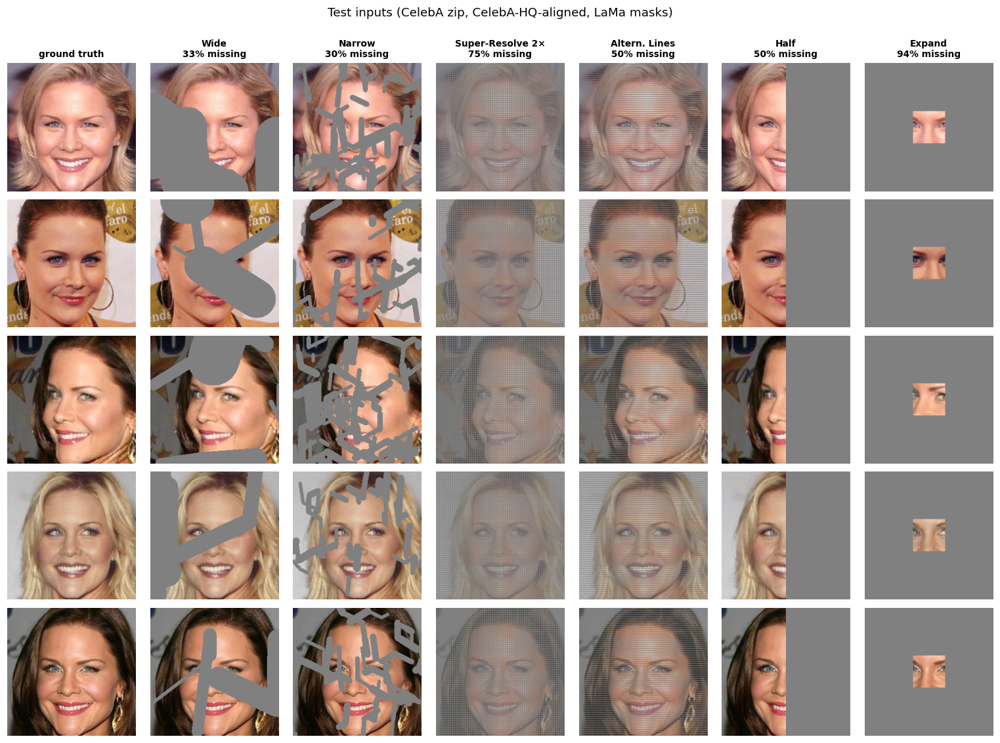

In [6]:
import cv2
OFFICIAL_MASK_DIR = {"wide": "thick", "narrow": "thin", "sr2x": "nn2", "altlines": "ev2li", "half": "genhalf", "expand": "ex64"}
IMG_EXT = {".png", ".jpg", ".jpeg"}

def center_crop_arr(pil_image, image_size=256):     # official RePaint / guided-diffusion preprocessing
    while min(*pil_image.size) >= 2 * image_size:
        pil_image = pil_image.resize(tuple(x // 2 for x in pil_image.size), resample=Image.BOX)
    scale = image_size / min(*pil_image.size)
    pil_image = pil_image.resize(tuple(round(x * scale) for x in pil_image.size), resample=Image.BICUBIC)
    arr = np.array(pil_image); cy, cx = (arr.shape[0] - image_size) // 2, (arr.shape[1] - image_size) // 2
    return arr[cy:cy + image_size, cx:cx + image_size]

def celebahq_align(pil, size=256):
    """CelebA-aligned (178x218) -> CelebA-HQ-style crop. Mean CelebA aligned landmarks:
    eyes (69,111) & (107,111), mouth corners (73,152) & (107,152)."""
    eye_l, eye_r = np.array([69., 111.]), np.array([107., 111.]); mouth = np.array([90., 152.])
    e0 = (eye_l + eye_r) / 2; x_vec = eye_r - eye_l; y_vec = mouth - e0
    s = max(np.linalg.norm(x_vec) * 4.0, np.linalg.norm(y_vec) * 3.6)
    c = e0 + 0.1 * y_vec
    sx, sy = pil.size[0] / 178, pil.size[1] / 218
    box = (c[0] * sx - s * sx / 2, c[1] * sy - s * sy / 2, c[0] * sx + s * sx / 2, c[1] * sy + s * sy / 2)
    return np.array(pil.convert("RGB").crop(tuple(int(round(v)) for v in box)).resize((size, size), Image.LANCZOS))

# ---- LaMa mask generators (fallback path), configs/data_gen/random_{thick,thin}_256.yaml ----
def _irregular(rng, H, W, max_angle, max_len, max_width, min_times, max_times):
    mask = np.zeros((H, W), np.float32)
    for i in range(rng.randint(min_times, max_times + 1)):
        sx, sy = rng.randint(W), rng.randint(H)
        for _ in range(1 + rng.randint(5)):
            angle = 0.01 + rng.randint(max_angle)
            if i % 2 == 0: angle = 2 * 3.1415926 - angle
            length, bw = 10 + rng.randint(max_len), 5 + rng.randint(max_width)
            ex, ey = int(np.clip(sx + length * np.sin(angle), 0, W)), int(np.clip(sy + length * np.cos(angle), 0, H))
            cv2.line(mask, (sx, sy), (ex, ey), 1.0, bw); sx, sy = ex, ey
    return mask

def _boxes(rng, H, W, margin, bmin, bmax, min_times, max_times):
    mask = np.zeros((H, W), np.float32); bmax = min(bmax, H - 2 * margin, W - 2 * margin)
    for _ in range(rng.randint(min_times, max_times + 1)):
        bw, bh = rng.randint(bmin, bmax), rng.randint(bmin, bmax)
        x0, y0 = rng.randint(margin, W - margin - bw + 1), rng.randint(margin, H - margin - bh + 1)
        mask[y0:y0 + bh, x0:x0 + bw] = 1
    return mask

def generated_mask(kind, seed, H=256, W=256):
    rng = np.random.RandomState(seed)
    if kind in ("wide", "narrow"):
        for _ in range(100):
            if kind == "wide":
                hole = _irregular(rng, H, W, 4, 200, 100, 1, 5) if rng.rand() < 1 / 1.3 else _boxes(rng, H, W, 10, 30, 150, 1, 3)
            else:
                hole = _irregular(rng, H, W, 4, 40, 10, 4, 50)
            if 0 < hole.mean() <= 0.5: break
    elif kind == "sr2x": hole = np.ones((H, W), np.float32); hole[::2, ::2] = 0
    elif kind == "altlines": hole = np.zeros((H, W), np.float32); hole[1::2, :] = 1
    elif kind == "half": hole = np.zeros((H, W), np.float32); hole[:, W // 2:] = 1
    elif kind == "expand": hole = np.ones((H, W), np.float32); c = (H - 64) // 2; hole[c:c + 64, c:c + 64] = 0
    return 1.0 - hole

def list_images(d): return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMG_EXT)

if DATASET_USED == "paper":
    gt_dir, mask_root = OFFICIAL
    pool = list_images(gt_dir)
    idx = (IMAGE_SELECTION if isinstance(IMAGE_SELECTION, (list, tuple))
           else sorted(random.Random(SEED).sample(range(len(pool)), k=min(N_IMAGES, len(pool)))))
    sel_paths = [pool[i] for i in idx]
    imgs = [center_crop_arr(Image.open(p).convert("RGB")) for p in sel_paths]
    MASKS = {}
    for k in MASK_TYPES:
        mfiles = list_images(mask_root / OFFICIAL_MASK_DIR[k])
        for j, i in enumerate(idx):
            m = center_crop_arr(Image.open(mfiles[i % len(mfiles)]).convert("RGB"))[..., 0] / 255.0
            MASKS[(k, j)] = torch.from_numpy((m > 0.5).astype(np.float32))[None]
    IMG_IDS = [f"hq{i:03d}" for i in idx]
else:
    zips = sorted(INPUT_ROOT.rglob("*.zip")) if INPUT_ROOT.exists() else []
    for z in zips:
        with zipfile.ZipFile(z) as zf: zf.extractall(ASSET_DIR / "zip_data")
    cands = [p for p in list((INPUT_ROOT if INPUT_ROOT.exists() else ASSET_DIR).rglob("celeba")) + list((ASSET_DIR / "zip_data").rglob("celeba"))
             if p.is_dir() and p.parent.name == "data"]
    assert cands, "No official data and no CelebA zip found — attach one of them."
    pool = list_images(cands[0])
    idx = (IMAGE_SELECTION if isinstance(IMAGE_SELECTION, (list, tuple))
           else sorted(random.Random(SEED).sample(range(len(pool)), k=min(N_IMAGES, len(pool)))))
    sel_paths = [pool[i] for i in idx]
    imgs = [celebahq_align(Image.open(p)) for p in sel_paths]
    MASKS = {(k, j): torch.from_numpy(generated_mask(k, SEED * 7 + 1000 * j + MASK_TYPES.index(k)).astype(np.float32))[None]
             for k in MASK_TYPES for j in range(len(idx))}
    IMG_IDS = [p.stem for p in sel_paths]

N_IMAGES = len(IMG_IDS)
X0 = torch.stack([torch.from_numpy(a.astype(np.float32) / 127.5 - 1).permute(2, 0, 1) for a in imgs])
def to_np_img(t): return ((t.float().clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()
def masked_view(x0, m): return to_np_img(x0 * m)
print("Images:", IMG_IDS, tuple(X0.shape))

fig, axes = plt.subplots(N_IMAGES, len(MASK_TYPES) + 1, figsize=(2.0 * (len(MASK_TYPES) + 1), 2.05 * N_IMAGES))
axes = np.atleast_2d(axes)
for i in range(N_IMAGES):
    axes[i, 0].imshow(to_np_img(X0[i]))
    for c, k in enumerate(MASK_TYPES): axes[i, c + 1].imshow(masked_view(X0[i], MASKS[(k, i)]))
axes[0, 0].set_title("ground truth", fontsize=9)
for c, k in enumerate(MASK_TYPES):
    axes[0, c + 1].set_title(f"{MASK_LABEL[k]}\n{float((1 - torch.stack([MASKS[(k, i)] for i in range(N_IMAGES)])).mean()) * 100:.0f}% missing", fontsize=9)
for a in axes.ravel(): a.axis("off")
fig.suptitle(f"Test inputs ({'official CelebA-HQ test set + paper masks' if DATASET_USED == 'paper' else 'CelebA zip, CelebA-HQ-aligned, LaMa masks'})", y=1.0)
plt.tight_layout(); show_and_log(fig, "data/inputs_and_masks")

## 5 · Diffusion prior (S1, S2) and benchmark
Both networks are wrapped behind one interface, `predict(x, k) -> (ε, log σ²)`:
* **paper**: guided-diffusion `UNetModel` (256 channels, attention at 32/16/8, scale-shift norm, learned σ) with the authors' weights. The second half of its 6 output channels is the variance interpolation coefficient *v*, and $\log\sigma^2_t = \tfrac{v+1}{2}\log\beta_t + \tfrac{1-v}{2}\log\tilde\beta_t$, computed on the **respaced** chain exactly as `SpacedDiffusion` does.
* **hf**: diffusers `UNet2DModel` with EMA weights and the fixed posterior variance $\tilde\beta_t$.

In [7]:
from diffusers import DDPMScheduler
BETAS_1000 = torch.linspace(1e-4, 0.02, 1000, dtype=torch.float64)        # linear schedule, both models
BASE_AC = torch.cumprod(1 - BETAS_1000, 0)

def build_paper_net(device):
    from guided_diffusion.script_util import create_model
    conf = types.SimpleNamespace(diffusion_steps=1000, use_value_logger=False)
    m = create_model(image_size=256, num_channels=256, num_res_blocks=2, channel_mult="", learn_sigma=True,
                     class_cond=False, use_checkpoint=False, attention_resolutions="32,16,8", num_heads=4,
                     num_head_channels=64, num_heads_upsample=-1, use_scale_shift_norm=True, dropout=0.0,
                     resblock_updown=True, use_fp16=USE_FP16, use_new_attention_order=False, conf=conf)
    m.load_state_dict(torch.load(PAPER_CKPT, map_location="cpu"))
    if USE_FP16: m.convert_to_fp16()
    return m.eval().requires_grad_(False).to(device)

def build_hf_net(device):
    from diffusers import UNet2DModel
    for mid in ["google/ddpm-ema-celebahq-256", "google/ddpm-celebahq-256"]:
        try:
            m = UNet2DModel.from_pretrained(mid); print("loaded", mid); break
        except Exception as e:
            print(mid, "failed:", str(e)[:120])
    if USE_FP16: m = m.half()
    return m.eval().requires_grad_(False).to(device)

class Prior:
    """Uniform interface over both networks: returns eps and (optionally) a learned variance coefficient."""
    def __init__(self, device):
        self.device = device
        self.kind = BACKEND_USED
        self.net = build_paper_net(device) if self.kind == "paper" else build_hf_net(device)
    @torch.inference_mode()
    def __call__(self, x, t_model):
        if self.kind == "paper":
            out = self.net(x, t_model)                       # guided-diffusion handles its own fp16 torso
            return out[:, :3].float(), out[:, 3:].float()
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            return self.net(x.half() if USE_FP16 else x, t_model).sample.float(), None

PRIORS = {d: Prior(d) for d in DEVICES}
print(f"{BACKEND_USED} prior: {sum(p.numel() for p in PRIORS[MAIN_DEVICE].net.parameters())/1e6:.0f} M params on {len(DEVICES)} device(s)")

# ---- OOM-safe batch size + throughput ----
def _time(bs, n=3):
    x = torch.randn(bs, 3, 256, 256, device=MAIN_DEVICE); t = torch.full((bs,), 500, device=MAIN_DEVICE, dtype=torch.long)
    PRIORS[MAIN_DEVICE](x, t)
    if IS_CUDA: torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n): PRIORS[MAIN_DEVICE](x, t)
    if IS_CUDA: torch.cuda.synchronize()
    return (time.time() - t0) / n
bench = []
for bs in ([16, 12, 8, 4, 2, 1] if MAX_BATCH_PER_GPU is None else [MAX_BATCH_PER_GPU]):
    try:
        s = _time(bs, 3 if IS_CUDA else 1); bench.append({"batch": bs, "sec_per_forward": s, "ms_per_image": 1000 * s / bs})
        if MAX_BATCH_PER_GPU is None: MAX_BATCH_PER_GPU = bs
        break
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
if not DRY_RUN and IS_CUDA:
    for bs in [1, 4]:
        if bs < MAX_BATCH_PER_GPU:
            s = _time(bs); bench.append({"batch": bs, "sec_per_forward": s, "ms_per_image": 1000 * s / bs})
BENCH = pd.DataFrame(bench).sort_values("batch")
SEC_PER_IMAGE_STEP = float(BENCH.ms_per_image.min()) / 1000
display(BENCH.round(4)); wlog({"perf/benchmark": wandb.Table(dataframe=BENCH)})
print(f"Batch per GPU: {MAX_BATCH_PER_GPU} | {SEC_PER_IMAGE_STEP*1000:.0f} ms per image-step"
      + (f" | peak mem {torch.cuda.max_memory_allocated(MAIN_DEVICE)/2**30:.1f} GB" if IS_CUDA else ""))

paper prior: 553 M params on 2 device(s)


,batch,sec_per_forward,ms_per_image
1,1,0.2184,218.3870
2,4,0.8194,204.8450
0,16,3.0400,189.9974


Batch per GPU: 16 | 190 ms per image-step | peak mem 8.8 GB


## 6 · Sampler: RePaint (Algorithm 1) + adaptive resampling (S5)

**Fixed schedule (the paper).** The schedule is the official `get_schedule_jump` (T = 250, j = 10, r = 10), run step by step. Each reverse step composites $x_{t-1} = m\odot x^{known}_{t-1} + (1-m)\odot x^{unknown}_{t-1}$ (Eq. 8). At each jump point, the state is diffused forward j steps and denoised again, r − 1 times. The sampler below is checked to reproduce the official transition sequence exactly.

**Adaptive resampling (our extension).** The paper uses r = 10 at every jump point, for every image and every mask. Resampling exists to *harmonise* the generated region with the context, and how much of that is still needed varies a lot: Alternating Lines is consistent almost immediately, while Expand or a wide stroke over an eye is not. The adaptive sampler measures this directly:

$$d_t \;=\; \frac{\sum \mathrm{pool}_4\!\big(|\hat x_0 - x_0|\big)\cdot \mathrm{pool}_4(B)}{\sum \mathrm{pool}_4(B)},\qquad B = m \odot \mathrm{dilate}_{16}(1-m)$$

* $\hat x_0$ is the network's single, globally consistent explanation of the *whole* image at time t.
* $B$ is the band of known pixels within 16 px of the hole.
* Wherever $\hat x_0$ disagrees with the real pixels next to the hole, the content being generated is not yet consistent with its surroundings. This is the boundary disharmony that the paper's Fig. 3 shows resampling removes.
* Pooling to ¼ resolution keeps the expected blur of $\hat x_0$ at high t from counting as disharmony.

Rules at every jump point, per sample:
1. Always do at least `r_min` passes.
2. Keep resampling while $d$ drops by more than `tol` relative to the best value so far, up to `r_max`.
3. Leave the jump point with the lowest-$d$ state (`keep_best`).
4. Finished samples are **removed from the batch**, so their compute is actually saved. On a T4 the cost per image is flat across batch sizes (see the benchmark), so wall time scales with the average number of passes, not the worst case.

In [8]:
def space_timesteps(num_train, n):
    if n >= num_train: return list(range(num_train))
    frac, cur, taken = (num_train - 1) / (n - 1), 0.0, []
    for _ in range(n): taken.append(round(cur)); cur += frac
    return sorted(set(taken))

def get_schedule_jump(t_T, n_sample=1, jump_length=10, jump_n_sample=10):
    """Official RePaint schedule (guided_diffusion/scheduler.py), used for cost estimates and self-checks."""
    jumps = {j: jump_n_sample - 1 for j in range(0, t_T - jump_length, jump_length)}
    t, ts = t_T, []
    while t >= 1:
        t -= 1; ts.append(t)
        if jumps.get(t, 0) > 0:
            jumps[t] -= 1
            for _ in range(jump_length): t += 1; ts.append(t)
    ts.append(-1)
    return ts

def n_unet_calls(T, j, r): ts = get_schedule_jump(T, 1, j, r); return sum(b < a for a, b in zip(ts[:-1], ts[1:]))

_RESPACED = {}
def respaced(T, device):
    key = (T, str(device))
    if key not in _RESPACED:
        use = space_timesteps(1000, T); ac = BASE_AC[use]
        ac_prev = torch.cat([torch.ones(1, dtype=ac.dtype), ac[:-1]]); betas = 1 - ac / ac_prev
        post_var = betas * (1 - ac_prev) / (1 - ac)
        post_logvar = torch.log(torch.cat([post_var[1:2], post_var[1:]]))           # "clipped", as guided-diffusion
        d = dict(sqrt_ac=ac.sqrt(), sqrt_1m_ac=(1 - ac).sqrt(), sqrt_ac_prev=ac_prev.sqrt(), sqrt_1m_ac_prev=(1 - ac_prev).sqrt(),
                 coef_x0=betas * ac_prev.sqrt() / (1 - ac), coef_xt=(1 - ac_prev) * (1 - betas).sqrt() / (1 - ac),
                 post_logvar=post_logvar, log_beta=torch.log(betas), sqrt_beta=betas.sqrt(), sqrt_1m_beta=(1 - betas).sqrt())
        d = {k: v.float().to(device) for k, v in d.items()}
        d["t_model"] = torch.tensor(use, dtype=torch.long, device=device)
        _RESPACED[key] = d
    return _RESPACED[key]

class NoiseStreams:
    """One RNG per sample: results are independent of batching, GPU count and which samples are still active."""
    def __init__(self, seeds, shape, device):
        self.g = [torch.Generator(device=device).manual_seed(int(s)) for s in seeds]; self.shape, self.device = shape, device
    def __call__(self, idx):
        return torch.stack([torch.randn(self.shape, generator=self.g[i], device=self.device) for i in idx])

def boundary_band(mask, band_px):
    hole = 1 - mask
    return mask * (F.max_pool2d(hole, 2 * band_px + 1, stride=1, padding=band_px) > 0).float()

@torch.inference_mode()
def repaint_sample(prior, x0, mask, seeds, T, jump_length, r, adaptive=None, capture_local=(), n_capture=10, counter=None):
    """Returns (samples, captures, stats). adaptive=None -> exact paper schedule; dict -> adaptive resampling."""
    dev, B = x0.device, x0.shape[0]
    S, noise = respaced(T, dev), NoiseStreams(seeds, x0.shape[1:], dev)
    all_idx = list(range(B))
    nfe = torch.zeros(B, dtype=torch.long)
    if adaptive:
        P = adaptive["pool"]
        band = F.avg_pool2d(boundary_band(mask, adaptive["band_px"]), P)
        band_sum = band.flatten(1).sum(1).clamp_min(1e-6)
    def disharmony(x0_hat, idx):
        err = F.avg_pool2d((x0_hat - x0[idx]).abs().mean(1, keepdim=True), P)
        return (err * band[idx]).flatten(1).sum(1) / band_sum[idx]

    def reverse(x, t, idx):                          # one Eq.-8 step from level t to t-1 for samples idx
        eps, v = prior(x, S["t_model"][t].expand(len(idx)))
        x0_hat = ((x - S["sqrt_1m_ac"][t] * eps) / S["sqrt_ac"][t]).clamp(-1, 1)
        mean = S["coef_x0"][t] * x0_hat + S["coef_xt"][t] * x
        m, g = mask[idx], x0[idx]
        if t > 0:
            logvar = S["post_logvar"][t] if v is None else ((v + 1) / 2) * S["log_beta"][t] + (1 - (v + 1) / 2) * S["post_logvar"][t]
            x_unknown = mean + torch.exp(0.5 * logvar) * noise(idx)                              # Eq. 8b
            x_known = S["sqrt_ac_prev"][t] * g + S["sqrt_1m_ac_prev"][t] * noise(idx)         # Eq. 8a
        else:
            x_unknown, x_known = mean, g
        nfe[idx] += 1
        if counter is not None: counter.update(len(idx))
        return m * x_known + (1 - m) * x_unknown, x0_hat                                      # Eq. 8c

    def undo(x, t, idx):                             # forward diffusion one step to level t (Eq. 1)
        return S["sqrt_1m_beta"][t] * x + S["sqrt_beta"][t] * noise(idx)

    cap_ts = set(np.linspace(T - 1, 0, n_capture).round().astype(int).tolist())
    captures, stats = [], {"rounds": [], "d_curves": []}
    jump_points = set(range(0, T - jump_length, jump_length))
    x = noise(all_idx)
    t = T - 1
    while t >= 0:
        x, x0_hat = reverse(x, t, all_idx)
        if capture_local and t in cap_ts:
            captures.append(dict(t=int(S["t_model"][t]), x_t=x[list(capture_local)].half().cpu(), x0_hat=x0_hat[list(capture_local)].half().cpu()))
        t -= 1
        if t not in jump_points:
            continue
        if not adaptive:                              # ---- paper: r-1 resampling rounds for everyone
            for _ in range(r - 1):
                for _ in range(jump_length): t += 1; x = undo(x, t, all_idx)
                for _ in range(jump_length): x, x0_hat = reverse(x, t, all_idx); t -= 1
            continue
        # ---- adaptive: per-sample rounds, converged samples leave the batch
        d_best = disharmony(x0_hat, all_idx); best_x = x.clone()
        rounds = torch.ones(B, dtype=torch.long)       # the pass just completed counts as pass 1
        active = list(all_idx); curve = [d_best.cpu()]
        t0 = t
        while active:
            xa = x[active]; ta = t0
            for _ in range(jump_length): ta += 1; xa = undo(xa, ta, active)
            for _ in range(jump_length): xa, x0a = reverse(xa, ta, active); ta -= 1
            x[active] = xa
            d = disharmony(x0a, active)
            rounds[active] += 1
            ai = torch.tensor(active, device=dev)
            better = d < d_best[ai]
            if adaptive.get("keep_best", True):
                best_x[ai[better]] = xa[better]
            improved = d < d_best[ai] * (1 - adaptive["tol"])
            d_best[ai] = torch.minimum(d_best[ai], d)
            dc = torch.full((B,), float("nan"), device=dev); dc[ai] = d; curve.append(dc.cpu())
            r_now = rounds[active]
            keep = ((r_now < adaptive["r_min"]) | improved.cpu()) & (r_now < adaptive["r_max"])
            active = [a for a, k in zip(active, keep.tolist()) if k]
        if adaptive.get("keep_best", True):
            x = best_x
        t = t0
        stats["rounds"].append((int(S["t_model"][t0]), rounds.tolist()))
        stats["d_curves"].append((int(S["t_model"][t0]), torch.stack(curve).tolist()))
    stats["nfe"] = nfe.tolist()
    return x.clamp(-1, 1), captures, stats

# ---------- self-checks against the official schedule ----------
class _CountingPrior:
    def __call__(self, x, t): return torch.zeros_like(x), None
for (T_, j_, r_) in [(250, 10, 10), (50, 5, 3), (40, 10, 1)]:
    _, _, st = repaint_sample(_CountingPrior(), torch.zeros(2, 3, 8, 8), torch.ones(2, 1, 8, 8), [0, 1], T_, j_, r_)
    assert st["nfe"] == [n_unet_calls(T_, j_, r_)] * 2, (T_, j_, r_, st["nfe"])
print(f"Sampler reproduces the official schedule: T=250, j=10, r=10 -> {n_unet_calls(250, 10, 10)} network evaluations per image")

Sampler reproduces the official schedule: T=250, j=10, r=10 -> 2410 network evaluations per image


## 7 · Multi-GPU runner with time budget and resume
Results are keyed by `(image, mask, seed, T, j, r, method)` and cached. To continue an interrupted run, attach the previous version's output as an input: any `samples_<backend>-<dataset>.pt` found under `/kaggle/input` is merged in at start.

In [9]:
CACHE_FILE = CACHE_DIR / f"samples_{RUN_TAG}.pt"
STORE = {"samples": {}, "captures": {}, "stats": {}}
for f in ([CACHE_FILE] + (sorted(INPUT_ROOT.rglob(CACHE_FILE.name)) if INPUT_ROOT.exists() else [])):
    if f.exists():
        old = torch.load(f)
        for k in STORE: STORE[k].update(old.get(k, {}))
        print(f"Resumed {len(old['samples'])} samples from {f}")
TIMINGS = []
ADA_TAG = "ada:" + ",".join(f"{k}={v}" for k, v in sorted(ADAPTIVE.items()))

def item_key(img, mask, seed, T, j, r, method="fixed"): return (int(img), mask, int(seed), int(T), int(j), int(r), method)
def base_seed(img, variant=0): return SEED + 1000 * img + 17 * variant

def est_cost(keys):
    tot = 0
    for k in keys:
        T, j, r, meth = k[3], k[4], k[5], k[6]
        tot += n_unet_calls(T, j, r) if meth == "fixed" else 0.75 * n_unet_calls(T, j, ADAPTIVE["r_max"])
    return tot * SEC_PER_IMAGE_STEP / len(DEVICES)

def run_items(items, label, capture_keys=(), required=False):
    todo = [k for k in dict.fromkeys(items) if k not in STORE["samples"]]
    if not todo:
        print(f"[{label}] all {len(items)} samples cached"); return {k: STORE["samples"][k] for k in items}
    est = est_cost(todo)
    print(f"[{label}] {len(todo)} samples, estimated {est/60:.0f} min | budget left {hours_left()*60:.0f} min")
    if est / 3600 > hours_left() and not required:
        print(f"[{label}] SKIPPED: does not fit in the time budget. Re-run with this output attached to resume.")
        return {k: STORE["samples"][k] for k in items if k in STORE["samples"]}
    groups = {}
    for k in todo: groups.setdefault(k[3:], []).append(k)
    units = []
    for (T, j, r, meth), ks in groups.items():
        for s in range(0, len(ks), MAX_BATCH_PER_GPU):
            units.append((len(ks[s:s + MAX_BATCH_PER_GPU]) * n_unet_calls(T, j, r), (T, j, r, meth), ks[s:s + MAX_BATCH_PER_GPU]))
    units.sort(key=lambda u: -u[0])
    q = queue.Queue(); [q.put(u) for u in units]
    lock, errors, done = threading.Lock(), [], [0]
    class Counter:
        def update(self, n):
            with lock: done[0] += n
    def worker(dev):
        try:
            while True:
                try: _, (T, j, r, meth), ks = q.get_nowait()
                except queue.Empty: return
                x0 = torch.stack([X0[k[0]] for k in ks]).to(dev)
                m = torch.stack([MASKS[(k[1], k[0])] for k in ks]).to(dev)
                cap = [i for i, k in enumerate(ks) if k in capture_keys]
                out, caps, st = repaint_sample(PRIORS[dev], x0, m, [k[2] for k in ks], T, j, r,
                                               adaptive=ADAPTIVE if meth != "fixed" else None,
                                               capture_local=cap, counter=Counter())
                out = out.half().cpu()
                with lock:
                    for i, k in enumerate(ks):
                        STORE["samples"][k] = out[i]
                        STORE["stats"][k] = {"nfe": st["nfe"][i],
                                             "rounds": [(t_, rs[i]) for t_, rs in st["rounds"]],
                                             "d_curve": [(t_, [c[i] for c in cs]) for t_, cs in st["d_curves"]]}
                    for ci, i in enumerate(cap):
                        STORE["captures"][ks[i]] = [dict(t=c["t"], x_t=c["x_t"][ci], x0_hat=c["x0_hat"][ci]) for c in caps]
        except Exception as e:
            errors.append(e)
    t0 = time.time()
    threads = [threading.Thread(target=worker, args=(d,), daemon=True) for d in DEVICES]
    [th.start() for th in threads]
    total = int(sum(u[0] for u in units))
    with tqdm(total=total, desc=label, unit="img-step", mininterval=3) as pbar:
        while any(th.is_alive() for th in threads):
            time.sleep(2); pbar.n = min(done[0], total); pbar.refresh()
        pbar.n = min(done[0], total); pbar.refresh()
    if errors: raise errors[0]
    dt = time.time() - t0
    TIMINGS.append({"experiment": label, "samples": len(todo), "minutes": dt / 60,
                    "network_evals": int(sum(STORE['stats'][k]['nfe'] for k in todo))})
    wlog({f"perf/minutes_{label}": dt / 60})
    torch.save(STORE, CACHE_FILE)
    print(f"[{label}] done in {dt/60:.1f} min")
    return {k: STORE["samples"][k] for k in items if k in STORE["samples"]}

MAIN_ITEMS = [item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE) for k in MASK_TYPES for i in range(N_IMAGES)]
BASE_ITEMS = [item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, 1) for k in MASK_TYPES for i in range(N_IMAGES)]
ADA_ITEMS  = [item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, ADAPTIVE["r_max"], ADA_TAG) for k in MASK_TYPES for i in range(N_IMAGES)]
DIV_ITEMS  = [item_key(0, k, base_seed(0, v), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE) for k in ["half", "expand"] if k in MASK_TYPES
              for v in range(1, N_DIVERSITY + 1)]
plan = pd.DataFrame([
    ("RePaint, paper settings", len(MAIN_ITEMS) + len(DIV_ITEMS), est_cost(MAIN_ITEMS + DIV_ITEMS) / 60, True),
    ("No resampling (r=1)", len(BASE_ITEMS), est_cost(BASE_ITEMS) / 60, RUN_BASELINE_NO_RESAMPLING),
    ("Adaptive resampling (est.)", len(ADA_ITEMS), est_cost(ADA_ITEMS) / 60, RUN_ADAPTIVE)],
    columns=["experiment", "samples", "est. minutes", "enabled"])
display(plan.round(0)); print(f"Time budget: {hours_left():.1f} h left")

,experiment,samples,est. minutes,enabled
0,"RePaint, paper settings",34,130.0,True
1,No resampling (r=1),30,12.0,True
2,Adaptive resampling (est.),30,129.0,True


Time budget: 10.0 h left


## 8 · Experiments
Priority order: (1) RePaint with the paper's settings, (2) the r = 1 baseline, (3) adaptive resampling.

In [10]:
main_out = run_items(MAIN_ITEMS + DIV_ITEMS, "repaint_paper", capture_keys={k for k in MAIN_ITEMS if k[0] == 0}, required=True)
for k in MAIN_ITEMS:
    Image.fromarray(to_np_img(main_out[k])).save(OUT_DIR / "samples" / f"{IMG_IDS[k[0]]}_{k[1]}_repaint.png")

[repaint_paper] 34 samples, estimated 130 min | budget left 598 min


repaint_paper:   0%|          | 0/81940 [00:00<?, ?img-step/s]

[repaint_paper] done in 150.2 min


In [11]:
base_out = run_items(BASE_ITEMS, "no_resampling_r1") if RUN_BASELINE_NO_RESAMPLING else {}

[no_resampling_r1] 30 samples, estimated 12 min | budget left 448 min


no_resampling_r1:   0%|          | 0/7500 [00:00<?, ?img-step/s]

[no_resampling_r1] done in 15.2 min


In [12]:
ada_out = run_items(ADA_ITEMS, "adaptive") if RUN_ADAPTIVE else {}
for k, v in ada_out.items():
    Image.fromarray(to_np_img(v)).save(OUT_DIR / "samples" / f"{IMG_IDS[k[0]]}_{k[1]}_adaptive.png")

[adaptive] 30 samples, estimated 129 min | budget left 433 min


adaptive:   0%|          | 0/108300 [00:00<?, ?img-step/s]

[adaptive] done in 79.7 min


## 9 · Evaluation against paper Table 1
LPIPS (AlexNet) on the full 256×256 image is the paper's metric (lower is better). PSNR, SSIM and hole-only PSNR are extra diagnostics. **v1** is your previous run (raw google DDPM on upscaled CelebA, different images), included as a reference point.

In [13]:
import lpips
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
LPIPS_FN = lpips.LPIPS(net="alex", verbose=False).to(MAIN_DEVICE).eval()

@torch.inference_mode()
def evaluate(outs, tag):
    rows, keys = [], list(outs)
    for s in range(0, len(keys), 16):
        ks = keys[s:s + 16]
        pred = torch.stack([outs[k].float() for k in ks]).to(MAIN_DEVICE); gt = torch.stack([X0[k[0]] for k in ks]).to(MAIN_DEVICE)
        lp = LPIPS_FN(pred, gt).flatten().cpu().numpy()
        for i, k in enumerate(ks):
            p8, g8 = to_np_img(pred[i]), to_np_img(gt[i]); hole = (1 - MASKS[(k[1], k[0])][0].numpy()).astype(bool)
            mse = ((p8[hole].astype(np.float64) - g8[hole]) ** 2).mean() if hole.any() else np.nan
            rows.append(dict(method=tag, image=IMG_IDS[k[0]], img_idx=k[0], mask=k[1], LPIPS=float(lp[i]),
                             PSNR=peak_signal_noise_ratio(g8, p8, data_range=255),
                             SSIM=structural_similarity(g8, p8, channel_axis=2, data_range=255),
                             hole_PSNR=10 * np.log10(255 ** 2 / mse) if mse > 0 else np.inf,
                             NFE=STORE["stats"].get(k, {}).get("nfe", np.nan)))
    return pd.DataFrame(rows)

TAG_MAIN, TAG_BASE, TAG_ADA = f"RePaint r={JUMP_N_SAMPLE} (v2)", "No resampling r=1 (v2)", "Adaptive RePaint (v2)"
dfs = [evaluate({k: main_out[k] for k in MAIN_ITEMS}, TAG_MAIN)]
if base_out: dfs.append(evaluate(base_out, TAG_BASE))
if ada_out: dfs.append(evaluate(ada_out, TAG_ADA))
df_all = pd.concat(dfs, ignore_index=True)
df_main = df_all[df_all.method == TAG_MAIN]; df_base = df_all[df_all.method == TAG_BASE]; df_ada = df_all[df_all.method == TAG_ADA]

PAPER_REPAINT = {"wide": 0.059, "narrow": 0.028, "sr2x": 0.029, "altlines": 0.009, "half": 0.165, "expand": 0.435}
PAPER_LAMA    = {"wide": 0.045, "narrow": 0.028, "sr2x": 0.177, "altlines": 0.083, "half": 0.138, "expand": 0.342}
V1_REPAINT    = {"wide": 0.098, "narrow": 0.051, "sr2x": 0.049, "altlines": 0.015, "half": 0.191, "expand": 0.469}

table1 = df_all.groupby(["mask", "method"]).LPIPS.mean().unstack("method").reindex(MASK_TYPES)
table1 = table1[[c for c in [TAG_MAIN, TAG_ADA, TAG_BASE] if c in table1]]
table1.insert(0, "v1 (your previous run)", [V1_REPAINT[k] for k in MASK_TYPES])
table1["Paper RePaint"] = [PAPER_REPAINT[k] for k in MASK_TYPES]
table1["Paper LaMa"] = [PAPER_LAMA[k] for k in MASK_TYPES]
table1["v2 − paper"] = table1[TAG_MAIN] - table1["Paper RePaint"]
table1.index = [MASK_LABEL[k] for k in MASK_TYPES]
table1.loc["Mean"] = table1.mean()
print(f"LPIPS ↓  ({N_IMAGES} images, backend={BACKEND_USED}, data={DATASET_USED})"); display(table1.round(3))
diag = df_all.groupby(["method", "mask"])[["LPIPS", "PSNR", "SSIM", "hole_PSNR", "NFE"]].mean().round(3)
display(diag)
wlog({"eval/table1_lpips": wandb.Table(dataframe=table1.reset_index().rename(columns={"index": "mask"})),
      "eval/all_metrics": wandb.Table(dataframe=diag.reset_index()), "eval/per_image": wandb.Table(dataframe=df_all)})
for k in MASK_TYPES:
    if wandb.run is not None:
        wandb.run.summary[f"lpips/{k}"] = df_main[df_main["mask"] == k].LPIPS.mean()
        if len(df_ada): wandb.run.summary[f"lpips_adaptive/{k}"] = df_ada[df_ada["mask"] == k].LPIPS.mean()
df_all.to_csv(OUT_DIR / "metrics_per_image.csv", index=False); table1.to_csv(OUT_DIR / "table1_lpips.csv")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 214MB/s] 


LPIPS ↓  (5 images, backend=paper, data=zip)


method,v1 (your previous run),RePaint r=10 (v2),Adaptive RePaint (v2),No resampling r=1 (v2),Paper RePaint,Paper LaMa,v2 − paper
Wide,0.098,0.086,0.100,0.095,0.059,0.045,0.027
Narrow,0.051,0.038,0.043,0.070,0.028,0.028,0.010
Super-Resolve 2×,0.049,0.043,0.048,0.284,0.029,0.177,0.014
Altern. Lines,0.015,0.017,0.019,0.056,0.009,0.083,0.008
Half,0.191,0.192,0.182,0.210,0.165,0.138,0.027
Expand,0.469,0.436,0.475,0.527,0.435,0.342,0.001
Mean,0.146,0.135,0.145,0.207,0.121,0.136,0.015


LPIPS    PSNR   SSIM  hole_PSNR     NFE
method                 mask                                             
Adaptive RePaint (v2)  altlines  0.019  38.681  0.975     35.671  1244.0
                       expand    0.475  10.906  0.306     10.626  1258.0
                       half      0.182  16.075  0.706     13.065  1250.0
                       narrow    0.043  28.780  0.913     23.325  1248.0
                       sr2x      0.048  34.277  0.943     33.027  1266.0
                       wide      0.100  22.315  0.842     17.367  1234.0
No resampling r=1 (v2) altlines  0.056  34.414  0.957     31.404   250.0
                       expand    0.527  10.130  0.277      9.850   250.0
                       half      0.210  14.180  0.660     11.169   250.0
                       narrow    0.070  26.391  0.878     20.936   250.0
                       sr2x      0.284  25.588  0.761     24.339   250.0
                       wide      0.095  21.939  0.826     16.991   250.0
RePaint r=10 (v2)      altlines  0.017  39.136  0.976     36.126  2410.0
                       expand    0.436   9.627  0.322      9.347  2410.0
                       half      0.192  13.606  0.689     10.596  2410.0
                       narrow    0.038  29.971  0.923     24.516  2410.0
                       sr2x      0.043  35.114  0.947     33.865  2410.0
                       wide      0.086  23.164  0.852     18.216  2410.0

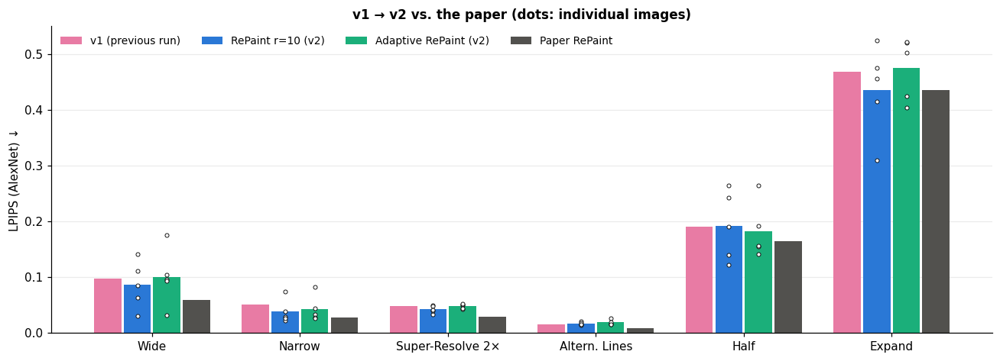

In [14]:
series = [("v1 (previous run)", [V1_REPAINT[k] for k in MASK_TYPES], C_V1, None),
          (TAG_MAIN, None, C_OURS, df_main)]
if len(df_ada): series.append((TAG_ADA, None, C_ADA, df_ada))
series.append(("Paper RePaint", [PAPER_REPAINT[k] for k in MASK_TYPES], C_PAPER, None))
fig, ax = plt.subplots(figsize=(12, 4.4)); x = np.arange(len(MASK_TYPES)); w = 0.8 / len(series)
for si, (name, vals, col, d) in enumerate(series):
    xs = x + (si - (len(series) - 1) / 2) * w
    vals = vals if vals is not None else [d[d["mask"] == k].LPIPS.mean() for k in MASK_TYPES]
    ax.bar(xs, vals, w * 0.92, color=col, label=name, zorder=2)
    if d is not None:
        for xi, k in zip(xs, MASK_TYPES):
            v = d[d["mask"] == k].LPIPS.values
            ax.scatter(np.full(len(v), xi), v, s=11, color="white", edgecolor="#0b0b0b", lw=0.6, zorder=3)
ax.set_xticks(x, [MASK_LABEL[k] for k in MASK_TYPES]); ax.set_ylabel("LPIPS (AlexNet) ↓")
ax.set_title("v1 → v2 vs. the paper (dots: individual images)"); ax.legend(frameon=False, ncol=4, fontsize=9)
ax.grid(axis="x", visible=False); plt.tight_layout(); show_and_log(fig, "eval/lpips_v1_v2_paper")

## 10 · Qualitative results

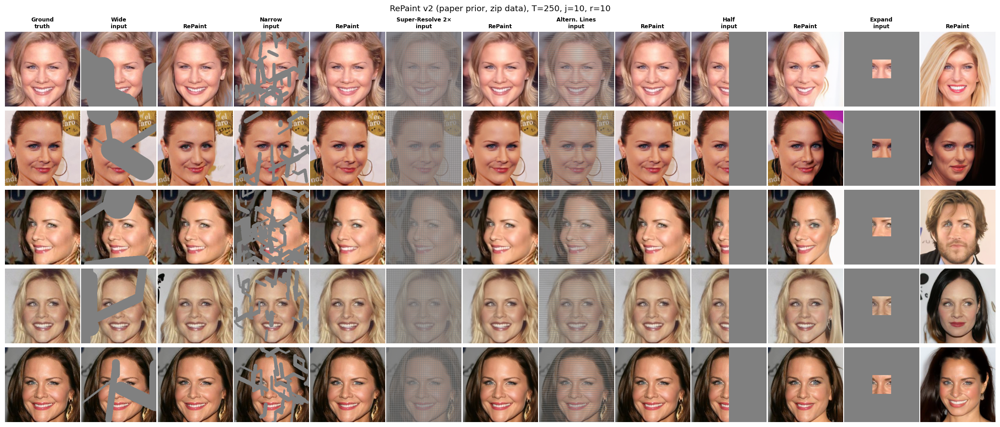

In [15]:
ncol = 2 * len(MASK_TYPES) + 1
fig, axes = plt.subplots(N_IMAGES, ncol, figsize=(1.55 * ncol, 1.6 * N_IMAGES + 0.6)); axes = np.atleast_2d(axes)
for i in range(N_IMAGES):
    axes[i, 0].imshow(to_np_img(X0[i]))
    for c, k in enumerate(MASK_TYPES):
        axes[i, 1 + 2 * c].imshow(masked_view(X0[i], MASKS[(k, i)]))
        axes[i, 2 + 2 * c].imshow(to_np_img(main_out[item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)]))
        if i == 0: axes[i, 1 + 2 * c].set_title(f"{MASK_LABEL[k]}\ninput", fontsize=8); axes[i, 2 + 2 * c].set_title("RePaint", fontsize=8)
axes[0, 0].set_title("Ground\ntruth", fontsize=8)
for a in axes.ravel(): a.axis("off")
fig.suptitle(f"RePaint v2 ({BACKEND_USED} prior, {DATASET_USED} data), T={T_STEPS}, j={JUMP_LENGTH}, r={JUMP_N_SAMPLE}", y=1.0)
plt.tight_layout(pad=0.2); show_and_log(fig, "results/overview_grid")

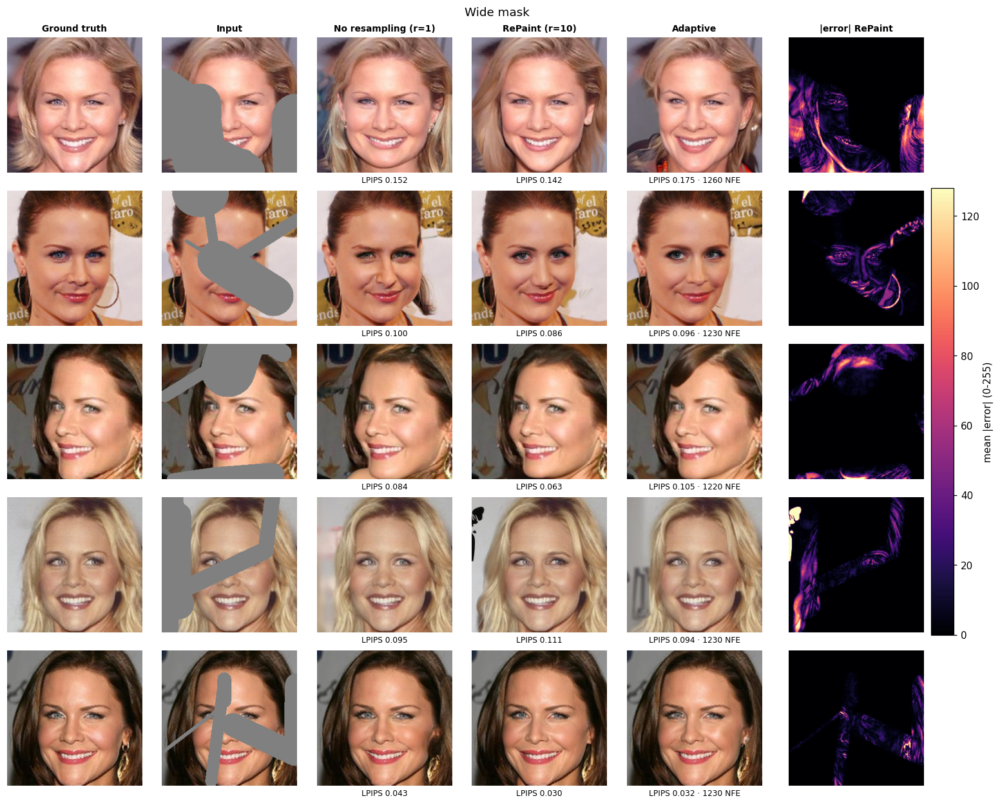

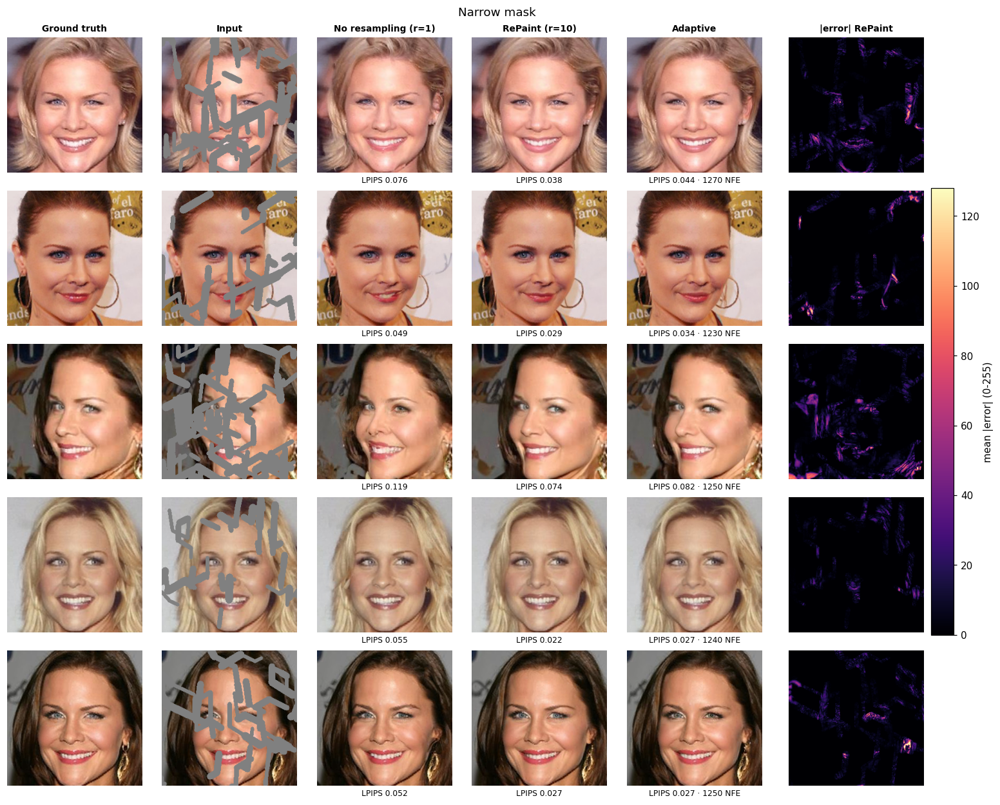

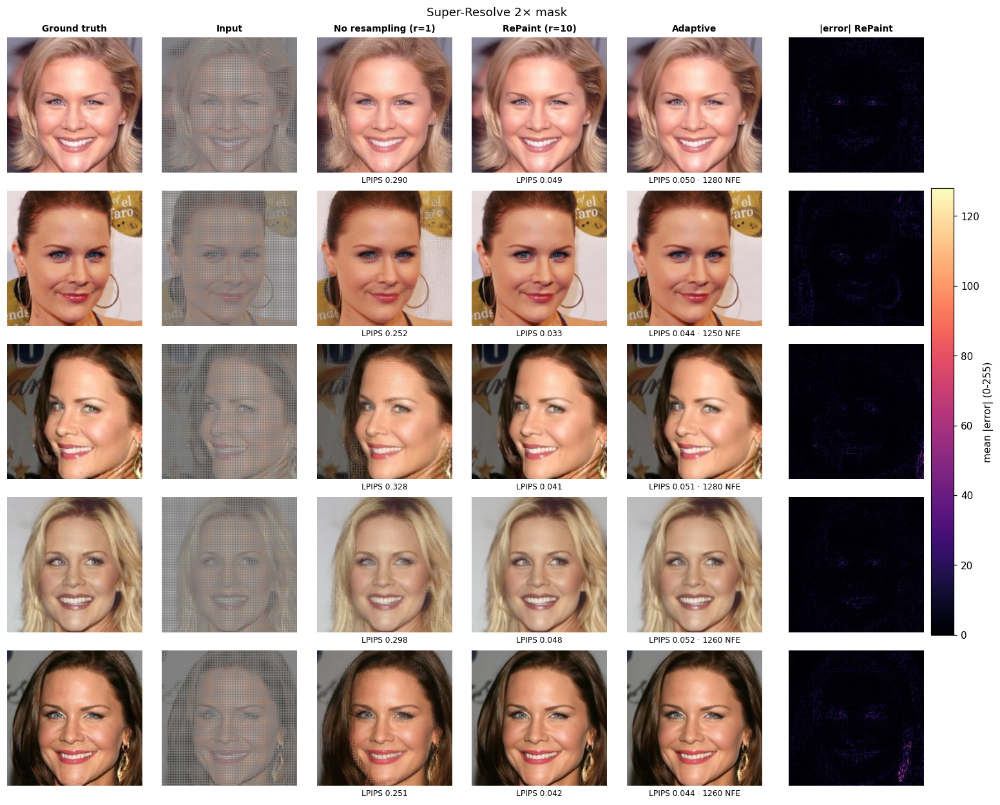

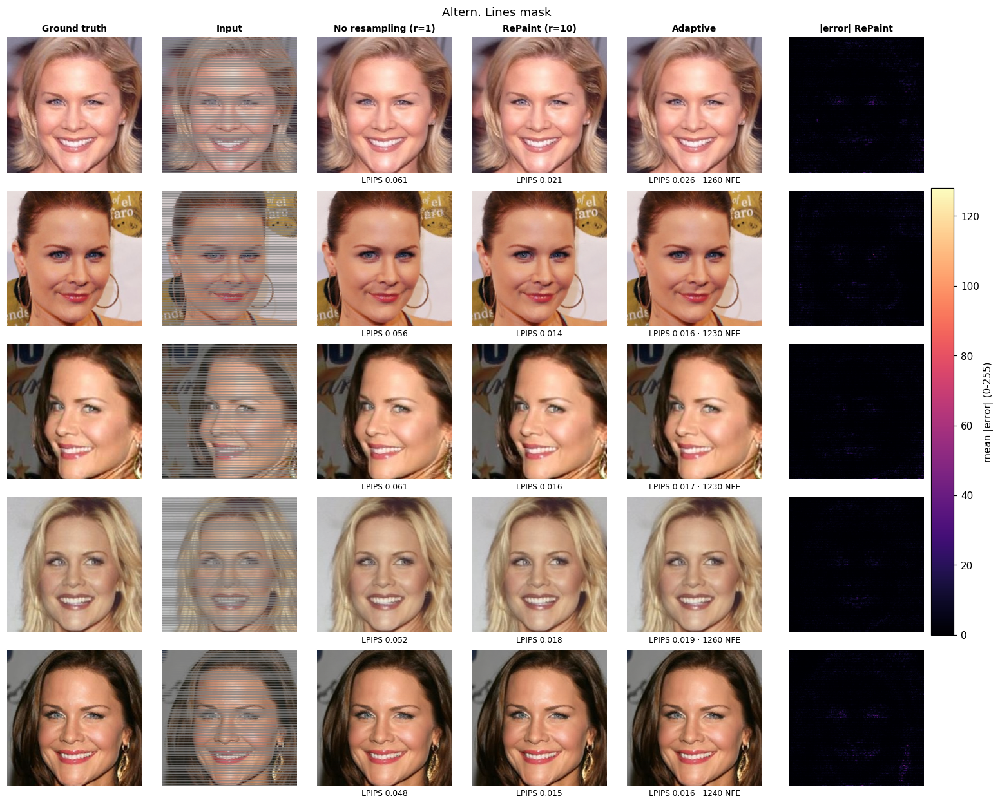

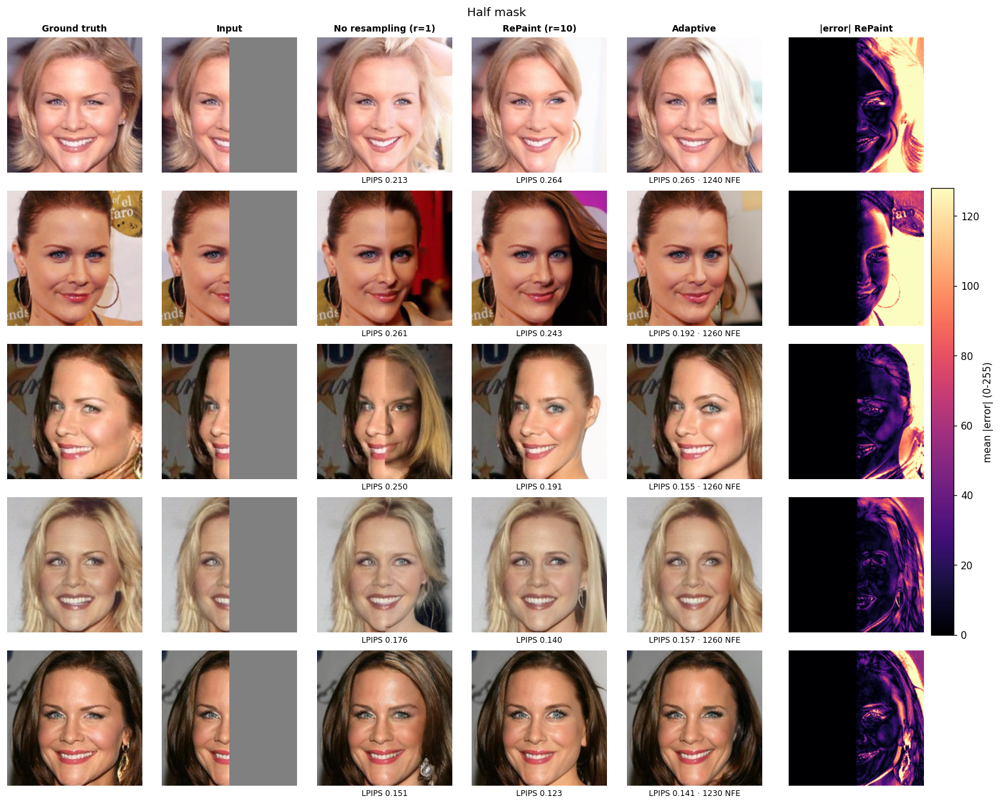

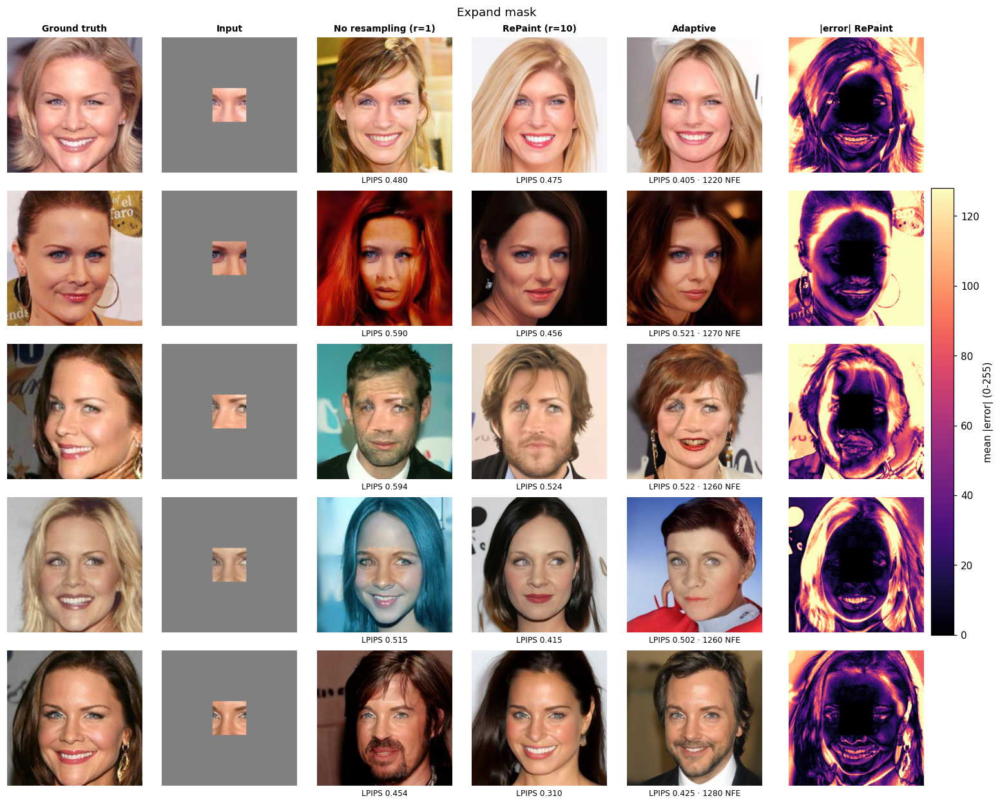

In [16]:
tbl = wandb.Table(columns=["image", "mask", "ground_truth", "input", "r1", "repaint", "adaptive", "abs_error",
                           "LPIPS_r1", "LPIPS_repaint", "LPIPS_adaptive", "NFE_adaptive"])
def _lp(df, i, k):
    r_ = df[(df.img_idx == i) & (df["mask"] == k)]; return float(r_.LPIPS.iloc[0]) if len(r_) else None
for k in MASK_TYPES:
    cols = ["Ground truth", "Input", "No resampling (r=1)", f"RePaint (r={JUMP_N_SAMPLE})", "Adaptive", "|error| RePaint"]
    fig, axes = plt.subplots(N_IMAGES, len(cols), figsize=(2.25 * len(cols) + 0.6, 2.25 * N_IMAGES), layout="constrained")
    axes = np.atleast_2d(axes)
    for i in range(N_IMAGES):
        km = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
        kb = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, 1)
        ka = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, ADAPTIVE["r_max"], ADA_TAG)
        gt, out = to_np_img(X0[i]), to_np_img(main_out[km]); blank = np.full_like(gt, 255)
        r1 = to_np_img(base_out[kb]) if kb in base_out else blank; ad = to_np_img(ada_out[ka]) if ka in ada_out else blank
        err = np.abs(out.astype(np.float32) - gt.astype(np.float32)).mean(2)
        for c, p in enumerate([gt, masked_view(X0[i], MASKS[(k, i)]), r1, out, ad]): axes[i, c].imshow(p)
        im = axes[i, 5].imshow(err, cmap="magma", vmin=0, vmax=128)
        for c, (d, kk) in zip([2, 3, 4], [(df_base, kb), (df_main, km), (df_ada, ka)]):
            v = _lp(d, i, k) if len(d) else None
            if v is not None:
                extra = f" · {STORE['stats'][kk]['nfe']} NFE" if c == 4 else ""
                axes[i, c].set_xlabel(f"LPIPS {v:.3f}{extra}", fontsize=8)
        tbl.add_data(IMG_IDS[i], MASK_LABEL[k], wandb.Image(gt), wandb.Image(masked_view(X0[i], MASKS[(k, i)])),
                     wandb.Image(r1), wandb.Image(out), wandb.Image(ad), wandb.Image((err / 128).clip(0, 1)),
                     _lp(df_base, i, k) if len(df_base) else None, _lp(df_main, i, k), _lp(df_ada, i, k) if len(df_ada) else None,
                     STORE["stats"].get(ka, {}).get("nfe"))
    for c, t_ in enumerate(cols): axes[0, c].set_title(t_, fontsize=9)
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False); [s.set_visible(False) for s in a.spines.values()]
    fig.colorbar(im, ax=axes[:, 5], shrink=0.6, label="mean |error| (0-255)"); fig.suptitle(f"{MASK_LABEL[k]} mask")
    show_and_log(fig, f"results/detail_{k}")
wlog({"results/comparison_table": tbl})

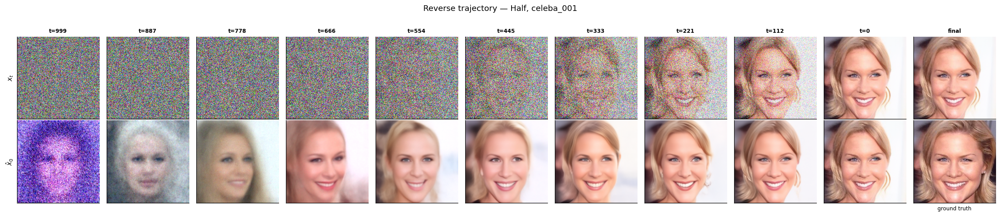

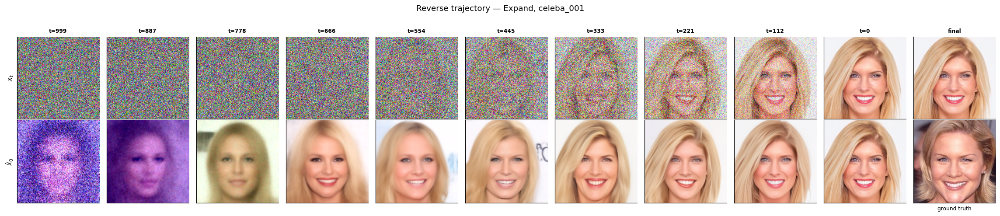

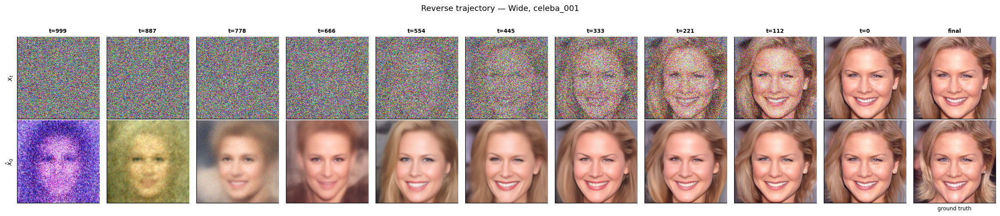

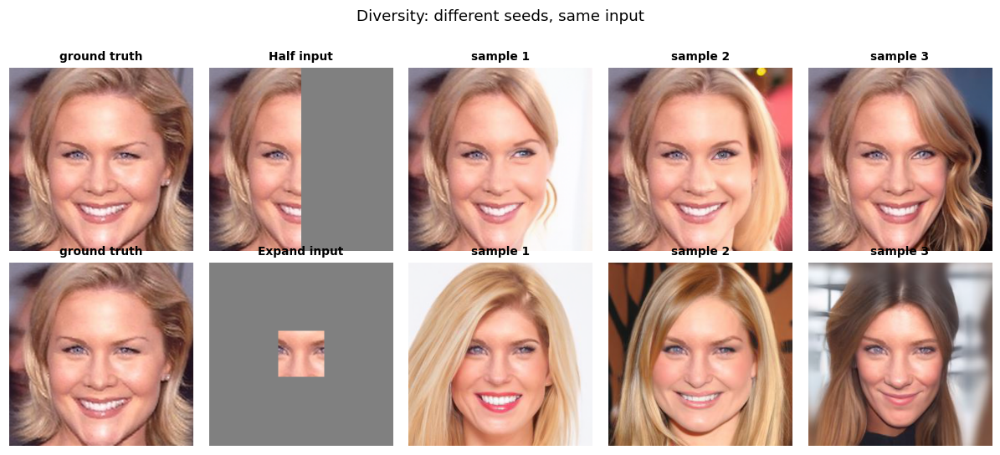

In [17]:
def plot_trajectory(k):
    key = item_key(0, k, base_seed(0), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE); caps = STORE["captures"].get(key)
    if not caps: return
    fig, axes = plt.subplots(2, len(caps) + 1, figsize=(1.9 * (len(caps) + 1), 4.3))
    for c, cp in enumerate(caps):
        axes[0, c].imshow(to_np_img(cp["x_t"])); axes[1, c].imshow(to_np_img(cp["x0_hat"])); axes[0, c].set_title(f"t={cp['t']}", fontsize=8)
    axes[0, -1].imshow(to_np_img(main_out[key])); axes[0, -1].set_title("final", fontsize=8)
    axes[1, -1].imshow(to_np_img(X0[0])); axes[1, -1].set_xlabel("ground truth", fontsize=8)
    axes[0, 0].set_ylabel("$x_t$"); axes[1, 0].set_ylabel(r"$\hat{x}_0$")
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle(f"Reverse trajectory — {MASK_LABEL[k]}, {IMG_IDS[0]}", y=1.02); plt.tight_layout(); show_and_log(fig, f"process/trajectory_{k}")
for k in ["half", "expand", "wide"]:
    if k in MASK_TYPES: plot_trajectory(k)

if N_DIVERSITY:
    dm = [k for k in ["half", "expand"] if k in MASK_TYPES]
    fig, axes = plt.subplots(len(dm), N_DIVERSITY + 3, figsize=(2.2 * (N_DIVERSITY + 3), 2.4 * len(dm))); axes = np.atleast_2d(axes)
    for r_, k in enumerate(dm):
        axes[r_, 0].imshow(to_np_img(X0[0])); axes[r_, 1].imshow(masked_view(X0[0], MASKS[(k, 0)]))
        axes[r_, 0].set_title("ground truth", fontsize=9); axes[r_, 1].set_title(f"{MASK_LABEL[k]} input", fontsize=9)
        for v in range(N_DIVERSITY + 1):
            axes[r_, 2 + v].imshow(to_np_img(main_out[item_key(0, k, base_seed(0, v), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)]))
            axes[r_, 2 + v].set_title(f"sample {v + 1}", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.suptitle("Diversity: different seeds, same input", y=1.02); plt.tight_layout(); show_and_log(fig, "results/diversity")

## 11 · Adaptive resampling analysis
Questions to answer: Does it match or beat fixed r = 10 in LPIPS? How much compute does it use? Where in the trajectory, and for which masks, does it spend the passes?

,LPIPS fixed r=10,LPIPS adaptive,NFE fixed,NFE adaptive,Δ LPIPS (adaptive − fixed),compute vs fixed
Wide,0.086,0.100,2410.0,1234.0,0.014,0.512
Narrow,0.038,0.043,2410.0,1248.0,0.005,0.518
Super-Resolve 2×,0.043,0.048,2410.0,1266.0,0.006,0.525
Altern. Lines,0.017,0.019,2410.0,1244.0,0.002,0.516
Half,0.192,0.182,2410.0,1250.0,-0.010,0.519
Expand,0.436,0.475,2410.0,1258.0,0.039,0.522
Mean,0.135,0.145,2410.0,1250.0,0.009,0.519


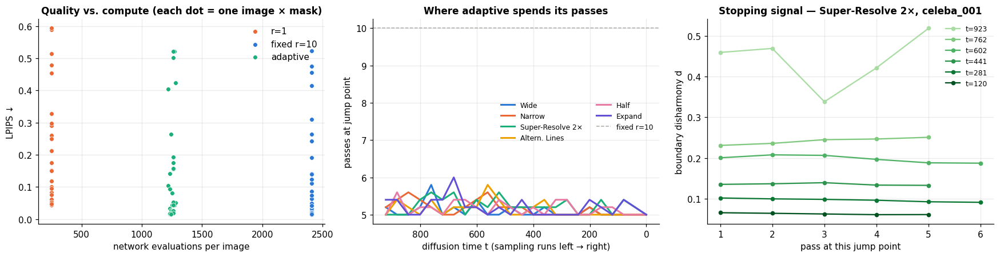

In [18]:
if len(df_ada):
    cmp_ = pd.DataFrame({
        f"LPIPS fixed r={JUMP_N_SAMPLE}": df_main.groupby("mask").LPIPS.mean(), "LPIPS adaptive": df_ada.groupby("mask").LPIPS.mean(),
        "NFE fixed": df_main.groupby("mask").NFE.mean(), "NFE adaptive": df_ada.groupby("mask").NFE.mean()}).reindex(MASK_TYPES)
    cmp_["Δ LPIPS (adaptive − fixed)"] = cmp_["LPIPS adaptive"] - cmp_[f"LPIPS fixed r={JUMP_N_SAMPLE}"]
    cmp_["compute vs fixed"] = cmp_["NFE adaptive"] / cmp_["NFE fixed"]
    cmp_.index = [MASK_LABEL[k] for k in MASK_TYPES]; cmp_.loc["Mean"] = cmp_.mean()
    display(cmp_.round(3)); wlog({"adaptive/summary": wandb.Table(dataframe=cmp_.reset_index().rename(columns={"index": "mask"}))})
    if wandb.run is not None:
        wandb.run.summary["adaptive/compute_ratio"] = float(cmp_.loc["Mean", "compute vs fixed"])
        wandb.run.summary["adaptive/delta_lpips"] = float(cmp_.loc["Mean", "Δ LPIPS (adaptive − fixed)"])

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    # (a) LPIPS vs compute, per sample
    for d, col, name in [(df_base, C_BASE, "r=1"), (df_main, C_OURS, f"fixed r={JUMP_N_SAMPLE}"), (df_ada, C_ADA, "adaptive")]:
        if len(d): axes[0].scatter(d.NFE, d.LPIPS, s=26, color=col, label=name, edgecolor="white", lw=0.5, zorder=3)
    axes[0].set(xlabel="network evaluations per image", ylabel="LPIPS ↓", title="Quality vs. compute (each dot = one image × mask)")
    axes[0].legend(frameon=False)
    # (b) passes per jump point over time, averaged per mask
    for ci, k in enumerate(MASK_TYPES):
        ks = [kk for kk in ADA_ITEMS if kk[1] == k and kk in STORE["stats"]]
        if not ks: continue
        ts_ = [t_ for t_, _ in STORE["stats"][ks[0]]["rounds"]]
        mean_r = np.mean([[r_ for _, r_ in STORE["stats"][kk]["rounds"]] for kk in ks], axis=0)
        axes[1].plot(ts_, mean_r, "-", lw=2, label=MASK_LABEL[k],
                     color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"][ci])
    axes[1].axhline(JUMP_N_SAMPLE, color=C_GRAY, ls="--", lw=1, label=f"fixed r={JUMP_N_SAMPLE}")
    axes[1].yaxis.set_major_locator(plt.MaxNLocator(integer=True)); axes[1].invert_xaxis(); axes[1].set(xlabel="diffusion time t (sampling runs left → right)", ylabel="passes at jump point", title="Where adaptive spends its passes")
    axes[1].legend(frameon=False, fontsize=8, ncol=2)
    # (c) disharmony curves at a few jump points, image 0, hardest mask
    k_hard = max(MASK_TYPES, key=lambda k: df_ada[df_ada["mask"] == k].NFE.mean())
    st = STORE["stats"].get(item_key(0, k_hard, base_seed(0), T_STEPS, JUMP_LENGTH, ADAPTIVE["r_max"], ADA_TAG))
    if st:
        sel = st["d_curve"][:: max(1, len(st["d_curve"]) // 5)]
        for (t_, curve), shade in zip(sel, np.linspace(0.35, 0.95, len(sel))):
            c_ = [v for v in curve if v == v]
            axes[2].plot(range(1, len(c_) + 1), c_, "o-", ms=4, lw=1.5, color=plt.cm.Greens(shade), label=f"t={t_}")
        axes[2].set(xlabel="pass at this jump point", ylabel="boundary disharmony d", title=f"Stopping signal — {MASK_LABEL[k_hard]}, {IMG_IDS[0]}")
        axes[2].legend(frameon=False, fontsize=8)
        axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout(); show_and_log(fig, "adaptive/analysis")

## 12 · Optional: paper ablations (Tables 2 and 3)
Off by default: v1 already ran them, and with the 553 M-parameter paper model they cost several hours. Enable them in the configuration cell if there is budget left.

In [19]:
PAPER_T3 = {(5, 1): 0.075, (5, 5): 0.072, (5, 10): 0.073, (10, 1): 0.088, (10, 5): 0.073, (10, 10): 0.068,
            (15, 1): 0.065, (15, 5): 0.063, (15, 10): 0.065}
if RUN_ABLATION_JR and "wide" in MASK_TYPES:
    out = run_items([item_key(i, "wide", base_seed(i), T_STEPS, j, r) for r in ABLATION_R for j in ABLATION_J for i in range(N_IMAGES)], "ablation_j_r")
    d = evaluate(out, "abl"); d["j"] = [k[4] for k in out]; d["r"] = [k[5] for k in out]
    t3 = d.groupby(["r", "j"]).LPIPS.mean().unstack("j")
    t3p = pd.DataFrame({j: [PAPER_T3.get((r, j), np.nan) for r in t3.index] for j in t3.columns}, index=t3.index)
    display(pd.concat({"ours": t3, "paper": t3p}, axis=1).round(4))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8)); both = np.concatenate([t3.values.ravel(), t3p.values.ravel()])
    for a, (nm, tab) in zip(axes, [("Ours", t3), ("Paper Table 3", t3p)]):
        im = a.imshow(tab.values, cmap="Blues_r", vmin=np.nanmin(both), vmax=np.nanmax(both)); a.grid(False)
        a.set_xticks(range(tab.shape[1]), [f"j={j}" for j in tab.columns]); a.set_yticks(range(tab.shape[0]), [f"r={r}" for r in tab.index])
        for (ri, ci), v in np.ndenumerate(tab.values):
            if v == v: a.text(ci, ri, f"{v:.3f}", ha="center", va="center", fontsize=10)
        a.set_title(nm)
    fig.colorbar(im, ax=axes, fraction=0.025); show_and_log(fig, "ablation/table3")
    wlog({"ablation/table3": wandb.Table(dataframe=t3.reset_index())})

if RUN_ABLATION_SLOWDOWN and "wide" in MASK_TYPES:
    keys = [item_key(i, "wide", base_seed(i), T, JUMP_LENGTH, 1) for T in SLOWDOWN_T for i in range(N_IMAGES)] + \
           [item_key(i, "wide", base_seed(i), SLOWDOWN_T[0], JUMP_LENGTH, r) for r in RESAMPLE_R for i in range(N_IMAGES)]
    out = run_items(keys, "ablation_slowdown"); d = evaluate(out, "abl"); d["T"] = [k[3] for k in out]; d["r"] = [k[5] for k in out]
    slow = d[d.r == 1].groupby("T").LPIPS.mean(); res = d[d["T"] == SLOWDOWN_T[0]].groupby("r").LPIPS.mean()
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.plot([n_unet_calls(T, JUMP_LENGTH, 1) for T in slow.index], slow.values, "o-", color=C_BASE, lw=2, label="slowing down (T↑, r=1)")
    ax.plot([n_unet_calls(SLOWDOWN_T[0], JUMP_LENGTH, r) for r in res.index], res.values, "s-", color=C_OURS, lw=2, label="resampling (r↑)")
    ax.set(xlabel="network evaluations", ylabel="LPIPS ↓", title="Table 2: slowing down vs. resampling"); ax.legend(frameon=False)
    plt.tight_layout(); show_and_log(fig, "ablation/table2")

## 13 · Summary and W&B finalisation

In [20]:
print("=" * 78); print(f"RePaint v2 | prior={BACKEND_USED} | data={DATASET_USED} | {N_IMAGES} images | T={T_STEPS} j={JUMP_LENGTH} r={JUMP_N_SAMPLE}"); print("=" * 78)
display(table1.round(3))
perf = pd.DataFrame(TIMINGS)
if len(perf): display(perf.round(1)); wlog({"perf/timings": wandb.Table(dataframe=perf)})
if wandb.run is not None:
    wandb.run.summary["lpips/mean_v2"] = float(df_main.LPIPS.mean())
    wandb.run.summary["lpips/mean_paper"] = float(np.mean(list(PAPER_REPAINT.values())))
    art = wandb.Artifact(f"repaint-v2-results-{RUN_TAG}", type="results")
    art.add_dir(str(FIG_DIR), name="figures"); art.add_dir(str(OUT_DIR / "samples"), name="samples")
    for f in OUT_DIR.glob("*.csv"): art.add_file(str(f))
    run.log_artifact(art)
WANDB_RUN_DIR = Path(run.dir).parent
wandb.finish()

RePaint v2 | prior=paper | data=zip | 5 images | T=250 j=10 r=10


method,v1 (your previous run),RePaint r=10 (v2),Adaptive RePaint (v2),No resampling r=1 (v2),Paper RePaint,Paper LaMa,v2 − paper
Wide,0.098,0.086,0.100,0.095,0.059,0.045,0.027
Narrow,0.051,0.038,0.043,0.070,0.028,0.028,0.010
Super-Resolve 2×,0.049,0.043,0.048,0.284,0.029,0.177,0.014
Altern. Lines,0.015,0.017,0.019,0.056,0.009,0.083,0.008
Half,0.191,0.192,0.182,0.210,0.165,0.138,0.027
Expand,0.469,0.436,0.475,0.527,0.435,0.342,0.001
Mean,0.146,0.135,0.145,0.207,0.121,0.136,0.015


,experiment,samples,minutes,network_evals
0,repaint_paper,34,150.2,81940
1,no_resampling_r1,30,15.2,7500
2,adaptive,30,79.7,37500


## 14 · What changed from v1, and why it improves the numbers

**S1 — The paper's prior instead of a generic one (largest effect).** RePaint never trains anything. Everything it generates comes from the unconditional DDPM, so the prior *is* the inpainting model. v1 used `google/ddpm-celebahq-256` with its **raw (non-EMA) weights**. Ho et al. report their CelebA-HQ results with an exponential moving average of the weights, and raw weights give noisier, less coherent samples: the smeared eyes in v1's Narrow and Wide results. The paper's numbers come from the authors' own ADM / guided-diffusion network: 553 M parameters (5× v1), attention at 32, 16 and 8 px, scale-shift normalisation, learned variance, and EMA weights. v2 loads exactly that checkpoint. If it cannot be downloaded, v2 still uses the **EMA** version of the Google model.

**S2 — Learned variance.** That network predicts the reverse-step variance Σθ as well as the noise. Using it, recomputed on the 250-step respaced chain the way `SpacedDiffusion` does, makes the T = 250 sampling chain match what the model was trained for. A fixed $\tilde\beta_t$ becomes a poor approximation when steps are skipped (respacing), and it adds excess noise in the hole.

**S3 — The paper's test data and masks.** v1's inputs were 178×218 CelebA photos, center-cropped and upscaled 1.44× to 256 px. Those images are blurrier than anything in CelebA-HQ, and their faces sit at a different scale and position. The prior therefore had to continue an off-distribution context, which shows up as Expand outputs at the wrong zoom. LPIPS also compared sharp generated texture against a blurry ground truth. v2 evaluates on the same CelebA-HQ test faces and the **same LaMa mask files** the paper used for Table 1, so every number is directly comparable.

**S4 — CelebA-HQ alignment (fallback path).** Without the official data, the CelebA crop now follows the CelebA-HQ construction rule (crop side = max(4 × eye distance, 3.6 × eye-to-mouth distance), centred just below the eyes). Faces then have the scale the prior expects.

**S5 — Adaptive resampling.** The paper resamples every jump point r = 10 times, whatever the image or mask. Resampling exists to harmonise the generated region with the context, so v2 measures harmony directly. The signal is the disagreement between the model's global prediction x̂₀ and the true pixels in a 16 px band around the hole, at ¼ resolution. v2 keeps resampling only while that disagreement is still falling (between 5 and 15 passes), keeps the most harmonious state, and removes converged samples from the batch. Section 11 shows the result: per-mask LPIPS against fixed r = 10, the compute ratio, and where along the trajectory the passes are spent. The `keep_best` rule makes it slightly more than a stopping rule, because it selects among candidates by a context-consistency score. That favours the most context-consistent completion, a mild bias toward fidelity over diversity.

**S6 — Engineering.** Best-first scheduling over 2 GPUs, OOM-safe batch sizing, a hard time budget, and resume-from-previous-output let the expensive paper model finish inside Kaggle's 12-hour limit.

**Caveats.**
* n = 5 images, against the paper's 100. Per-mask means move by about ±0.01–0.03 LPIPS between image subsets, so compare trends, not third decimals.
* On the fallback path (`hf` prior and/or `zip` data), the remaining gap to the paper comes from the weaker prior and the CelebA domain. It is expected, and is not a sampler error.

## 15 · Download the results
Creates `/kaggle/working/repaint_v2_results.zip`. The file also appears in the **Output** tab after *Save Version → Save & Run All*. Attach that output to a later run to resume or extend it.

In [21]:
INCLUDE_CACHE = True      # the cache lets a later run resume; set False for a small zip
(OUT_DIR / "inputs").mkdir(exist_ok=True)
for i, name in enumerate(IMG_IDS):
    Image.fromarray(to_np_img(X0[i])).save(OUT_DIR / "inputs" / f"{name}_gt.png")
    for k in MASK_TYPES:
        Image.fromarray((MASKS[(k, i)][0].numpy() * 255).astype(np.uint8)).save(OUT_DIR / "inputs" / f"{name}_mask_{k}.png")
(OUT_DIR / "run_config.json").write_text(json.dumps(dict(
    backend=BACKEND_USED, dataset=DATASET_USED, images=IMG_IDS, T=T_STEPS, j=JUMP_LENGTH, r=JUMP_N_SAMPLE,
    adaptive=ADAPTIVE if RUN_ADAPTIVE else None, seed=SEED, fp16=USE_FP16, n_gpus=len(DEVICES), batch_per_gpu=MAX_BATCH_PER_GPU,
    timings=TIMINGS, wandb_project=WANDB_PROJECT, wandb_run=WANDB_RUN_NAME), indent=2, default=str))
zip_path = WORKING_ROOT / "repaint_v2_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(OUT_DIR.rglob("*")):
        if f.is_file() and (INCLUDE_CACHE or CACHE_DIR not in f.parents): zf.write(f, f.relative_to(OUT_DIR))
    if WANDB_MODE == "offline":
        for f in WANDB_RUN_DIR.rglob("*"):
            if f.is_file(): zf.write(f, Path("wandb_offline_run") / f.relative_to(WANDB_RUN_DIR))
with zipfile.ZipFile(zip_path) as zf: names = zf.namelist()
print(f"{zip_path}: {zip_path.stat().st_size/2**20:.1f} MB, {len(names)} files")
for folder in ["figures/", "samples/", "inputs/", "cache/", "wandb_offline_run/"]:
    n = sum(x.startswith(folder) for x in names)
    if n: print(f"  {folder:<20}{n}")
from IPython.display import FileLink, display
os.chdir(WORKING_ROOT); display(FileLink(zip_path.name, result_html_prefix="Download: "))

/kaggle/working/repaint_v2_results.zip: 99.4 MB, 113 files
  figures/            14
  samples/            60
  inputs/             35
  cache/              1


/kaggle/working/repaint_v2_results.zip